# Experiments from October 12 on
See tex/main.pdf, Sections 2.4 to 2.6. 

In [17]:
%run base.ipynb

mare


## Union bound

We plot
\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \sqrt{\frac{d}{n}}
\end{equation}
obtained by Theorem 2.5 in Section 2 and $\log \vert\mathcal H_d\vert \le d$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


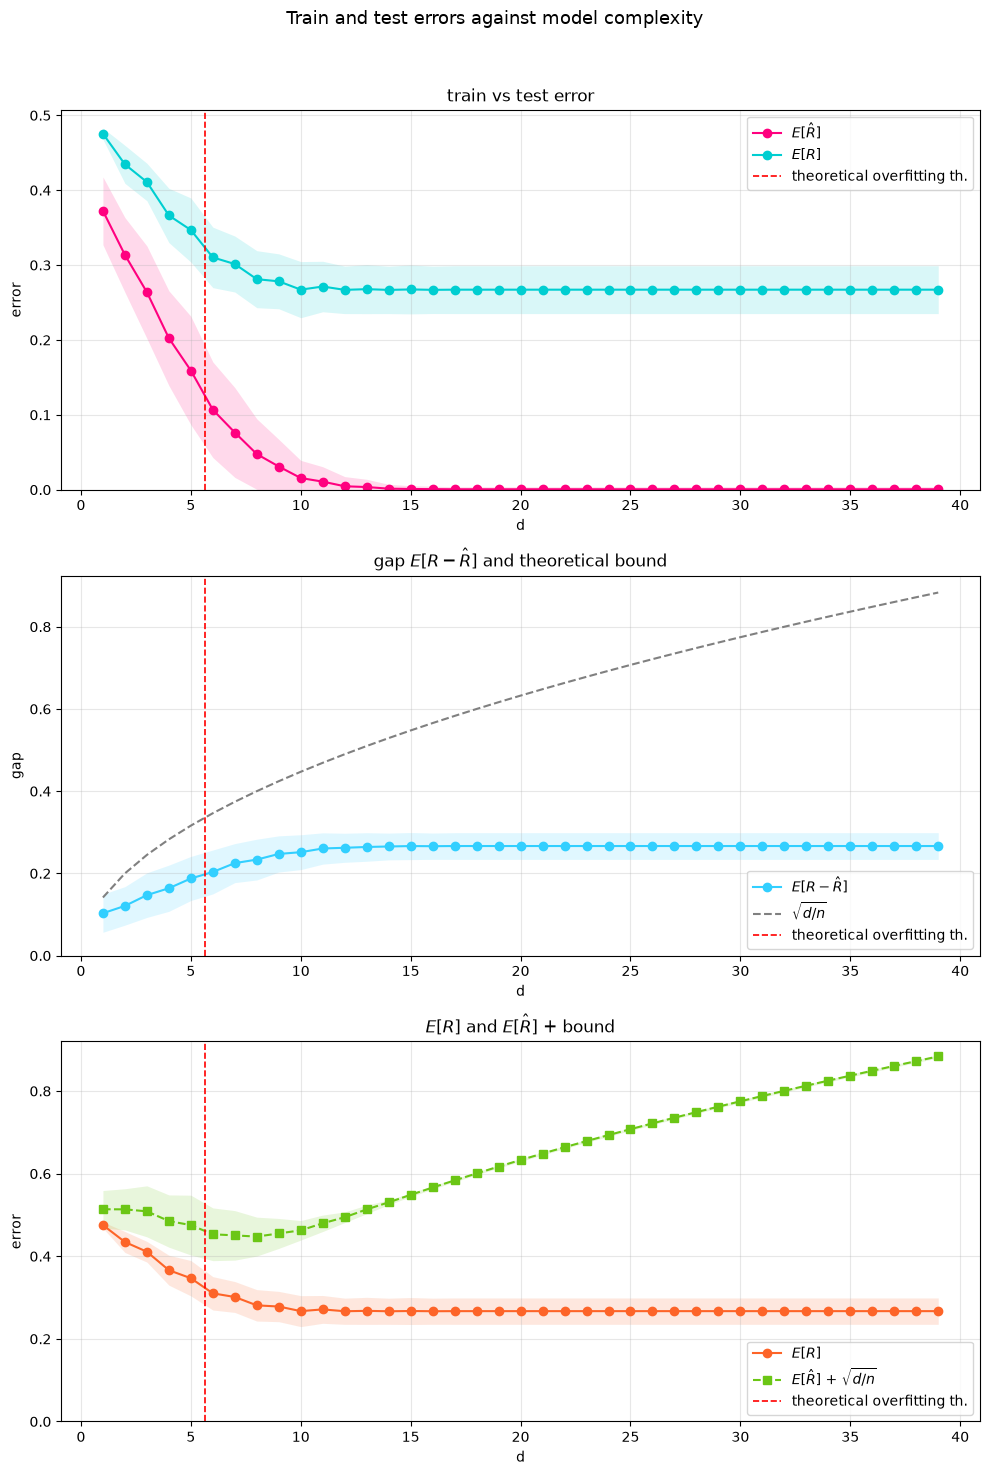

In [11]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
noise_std = 3
num_iter = 100
num_crossings = 10

from functools import partial
mysine = partial(sine, m = num_crossings)

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x = x_test, f = mysine, sigma = noise_std)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "unionbound", bound_params = {}
      )

## Rademacher + Massart

We plot

\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \min\left\{\sqrt{\frac{d}{n}}, 1\right\}
\end{equation}

obtained from $N(D) \le \min\{\vert \mathcal H\vert, 2^n\}$, equation (58). 

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


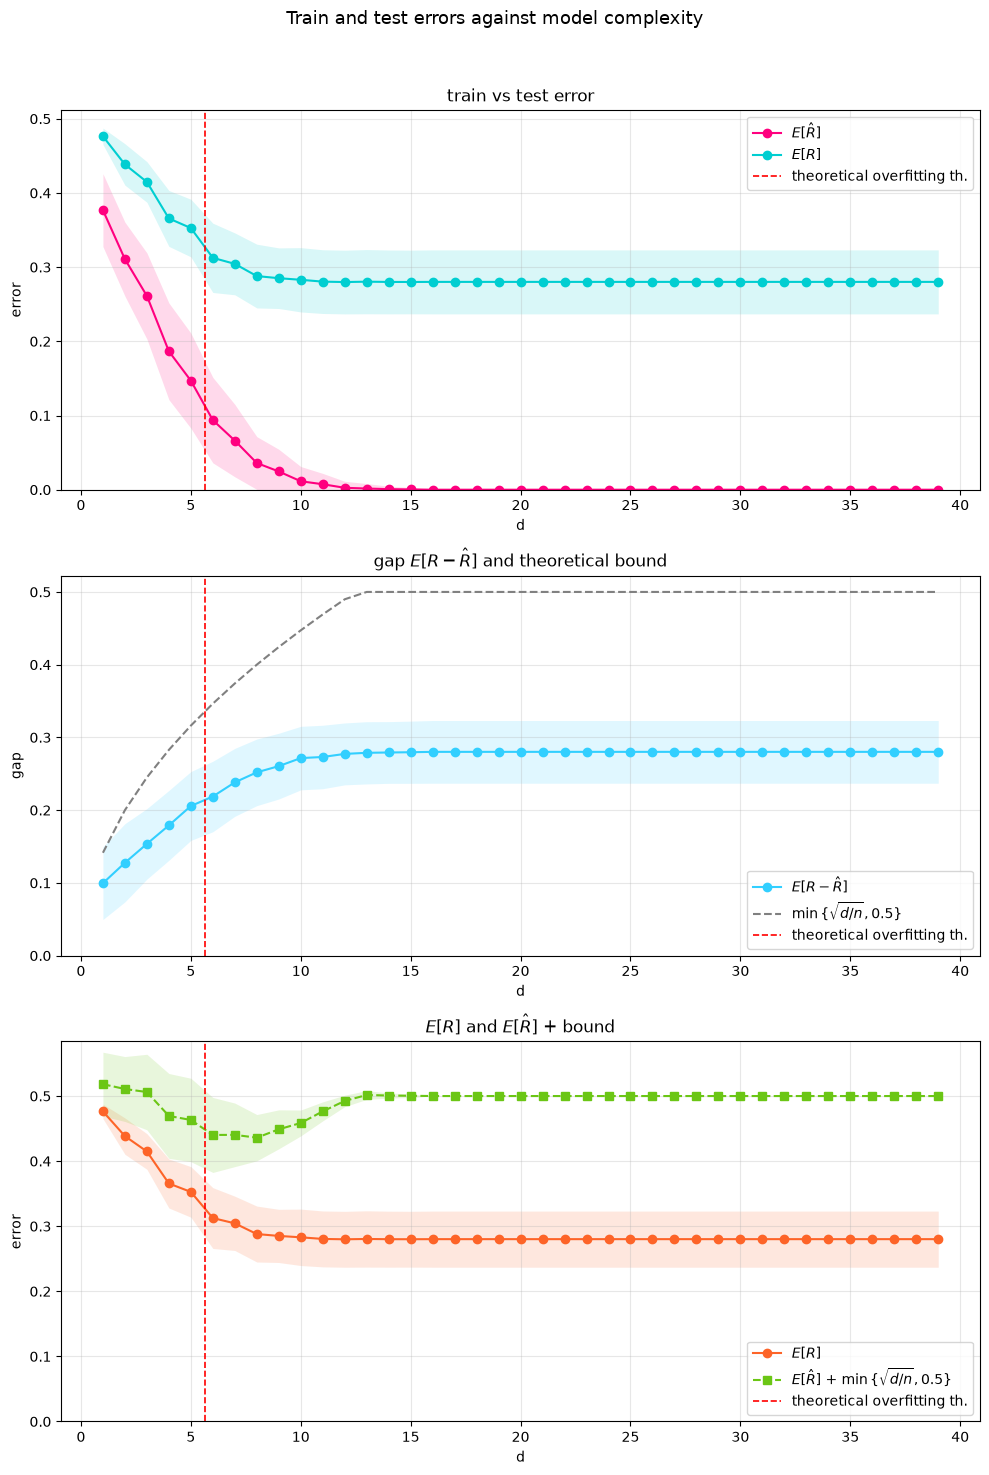

In [12]:
# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "rademmassart", bound_params = {}
      )

### vedi che non si sposta con il rumore!

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


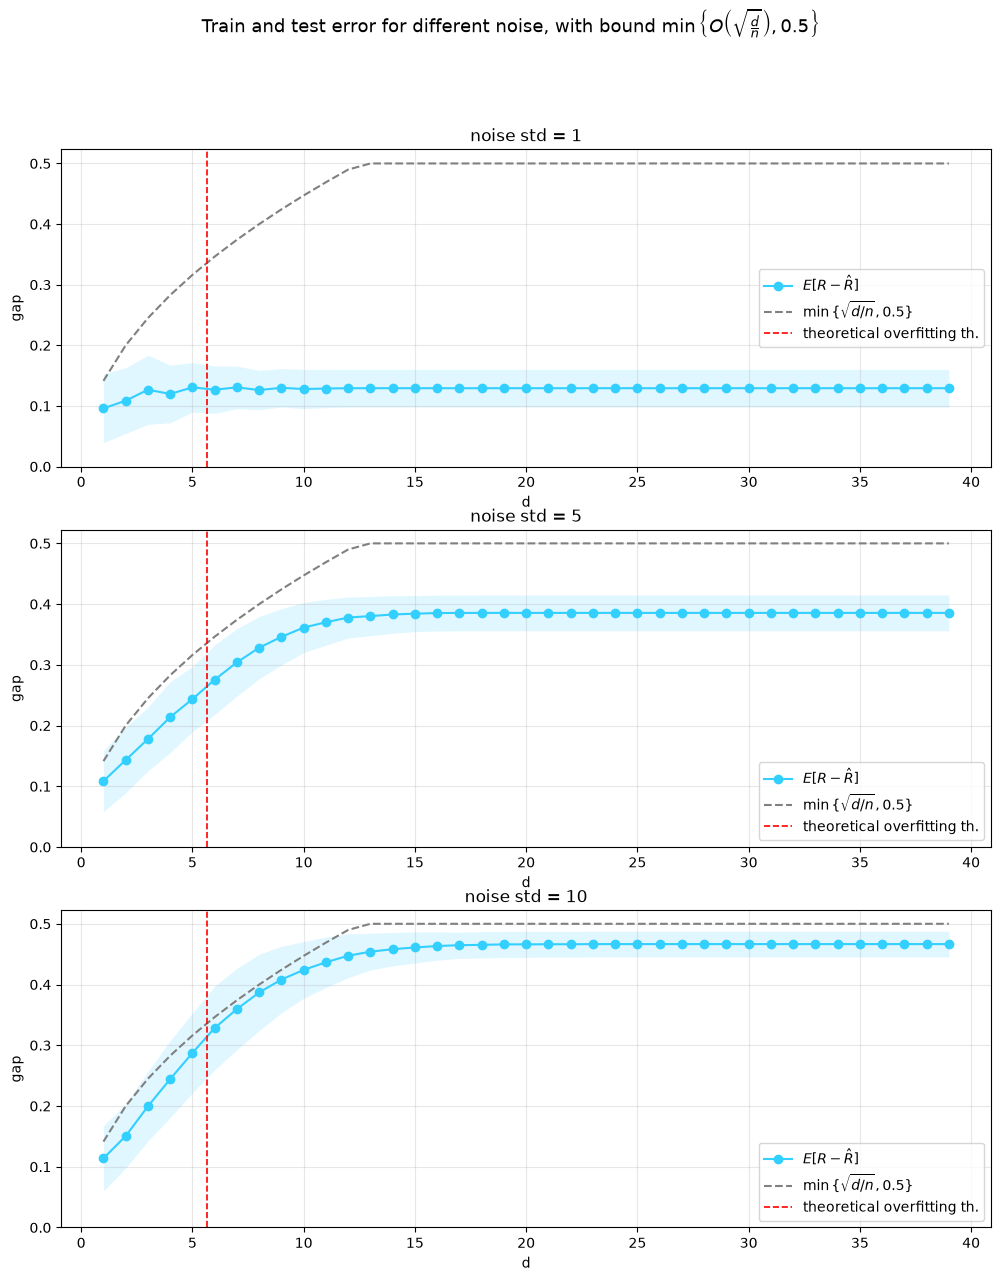

In [13]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle(r'Train and test error for different noise, with bound $\min\left\{O\left(\sqrt{\frac{d}{n}}\right), 0.5\right\}$', fontsize=13)

# noises
my_noise_stds = [1, 5, 10]

for ax, my_noise_std in zip(axs.flat, my_noise_stds):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=mysine, sigma=my_noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, f=mysine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.set_title(f'noise std = {my_noise_std}')

# Runtime ~2 min for 3 noise stds

## Bounds with the best risk

The bound is 

\begin{equation}

 \min\left\{ 
\sqrt{\frac{(A_{\mathcal H}+\sigma^2)\log \vert\mathcal H \vert}{n}} + \frac{\log\vert\mathcal H \vert}{n} ,
\sqrt{A_{\mathcal H}+\sigma^2} \right\}

\end{equation}

In [3]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
num_iter = 100
num_crossings = 10
noise_par = 0.8

from functools import partial
mysine = partial(sine, m = num_crossings)

Let's first see the Bayes risk (irreducible noise), the minimum risk achievable by our hypotheses, and their difference (approximation error). 

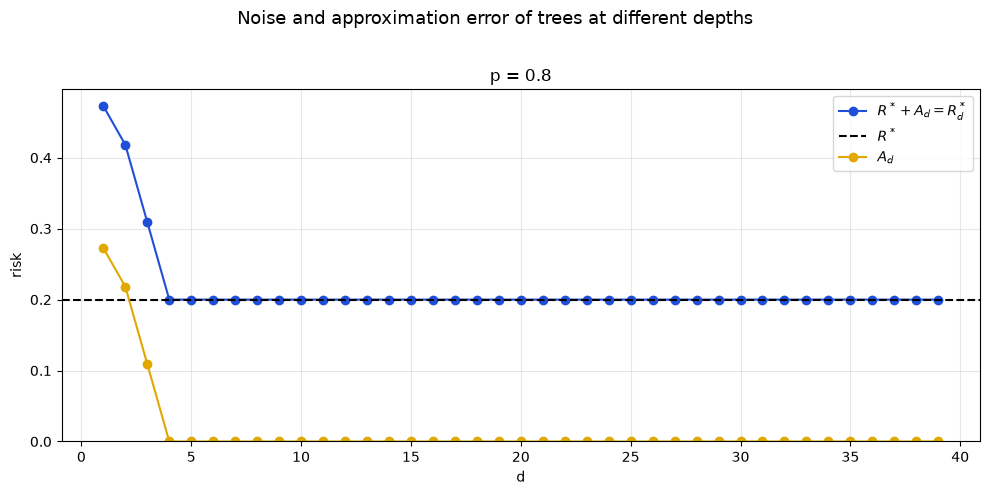

In [8]:
# same depths that main_loop and plots use
depths, _ = get_depths_list(np.log2(data_size_tr), mymodel)

R_star_d = dp_R_star_d(mysine, depths, N = supp_size, p = noise_par)

R_star = 1-noise_par

A_d = R_star_d - R_star

def plot_noise_approxerr(ax, depths, R_star_d, R_star):
    # colors on purpose different from the ones used in plots() for the errors
    ax.plot(depths, R_star_d, color='#1F4FD8', marker='o', label=r'$R^* + A_d = R^*_d$')
    ax.axhline(R_star, color='k', linestyle='--', label=r'$R^*$')
    ax.plot(depths, R_star_d - R_star, color='#E0A800', marker='o', label=r'$A_d$')
    ax.set_ylim(bottom=0)
    ax.set_xlabel('d'); ax.set_ylabel('risk')
    ax.legend(); ax.grid(True, alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Noise and approximation error of trees at different depths', fontsize=13)
plot_noise_approxerr(ax, depths, R_star_d, R_star)
ax.set_title(f'p = {noise_par}')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [16]:
%run base.ipynb

mare


[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


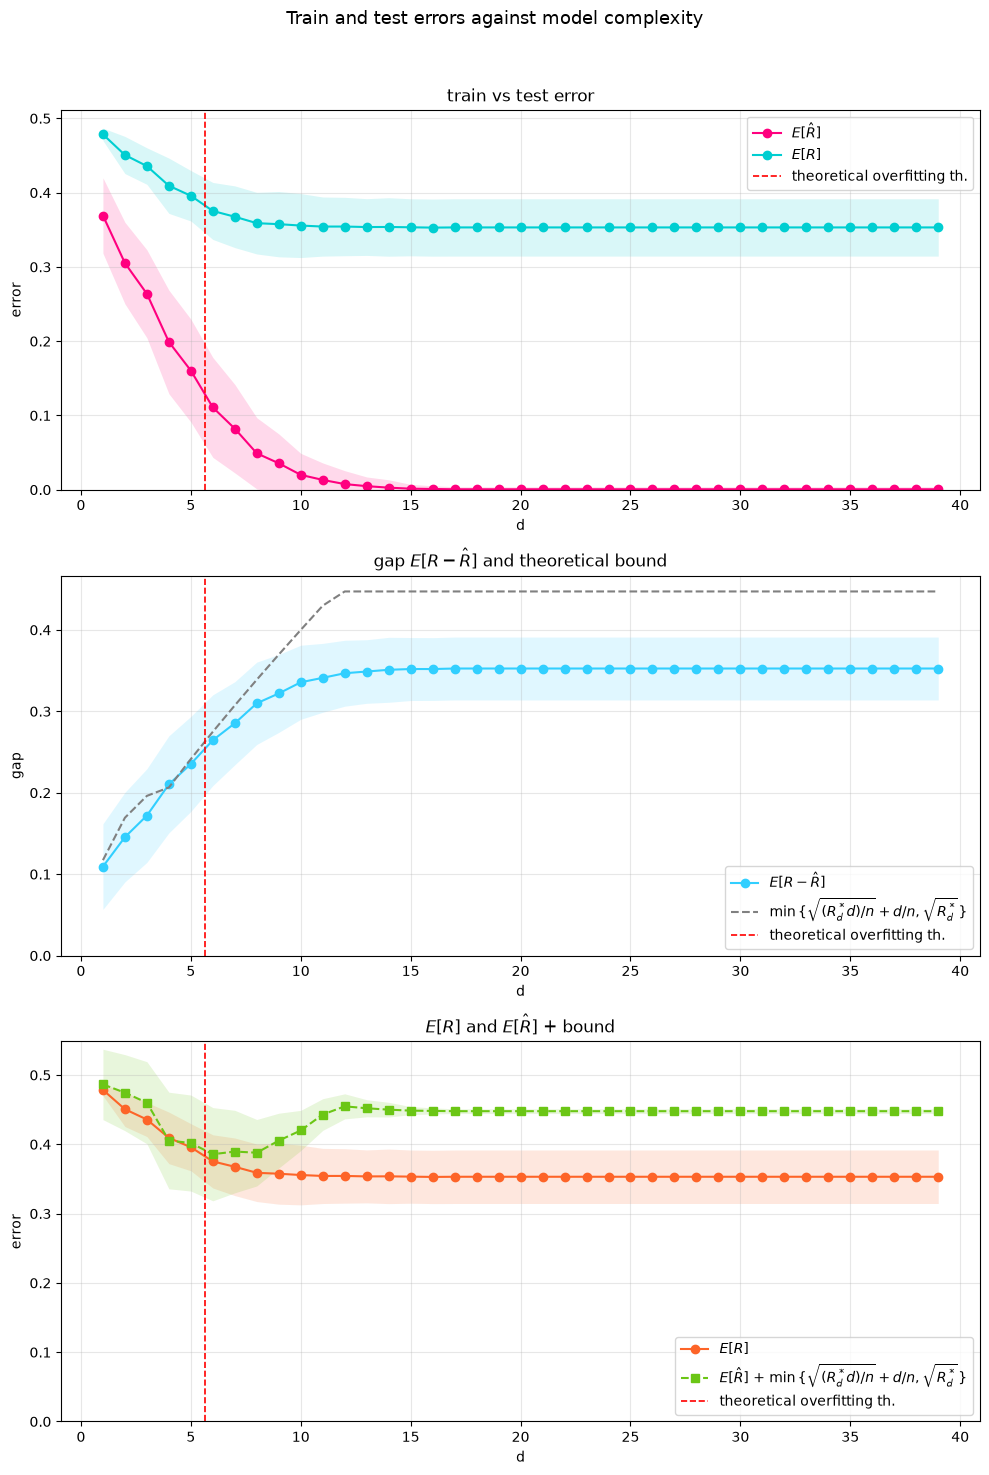

In [17]:

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x = x_test, f = mysine, p = noise_par)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, p = noise_par, T = num_iter, model = mymodel,
    f = mysine, noise_type = "bernoulli",
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_par, T= num_iter, model = mymodel, 
      bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d}
      )

Let's see it changing!

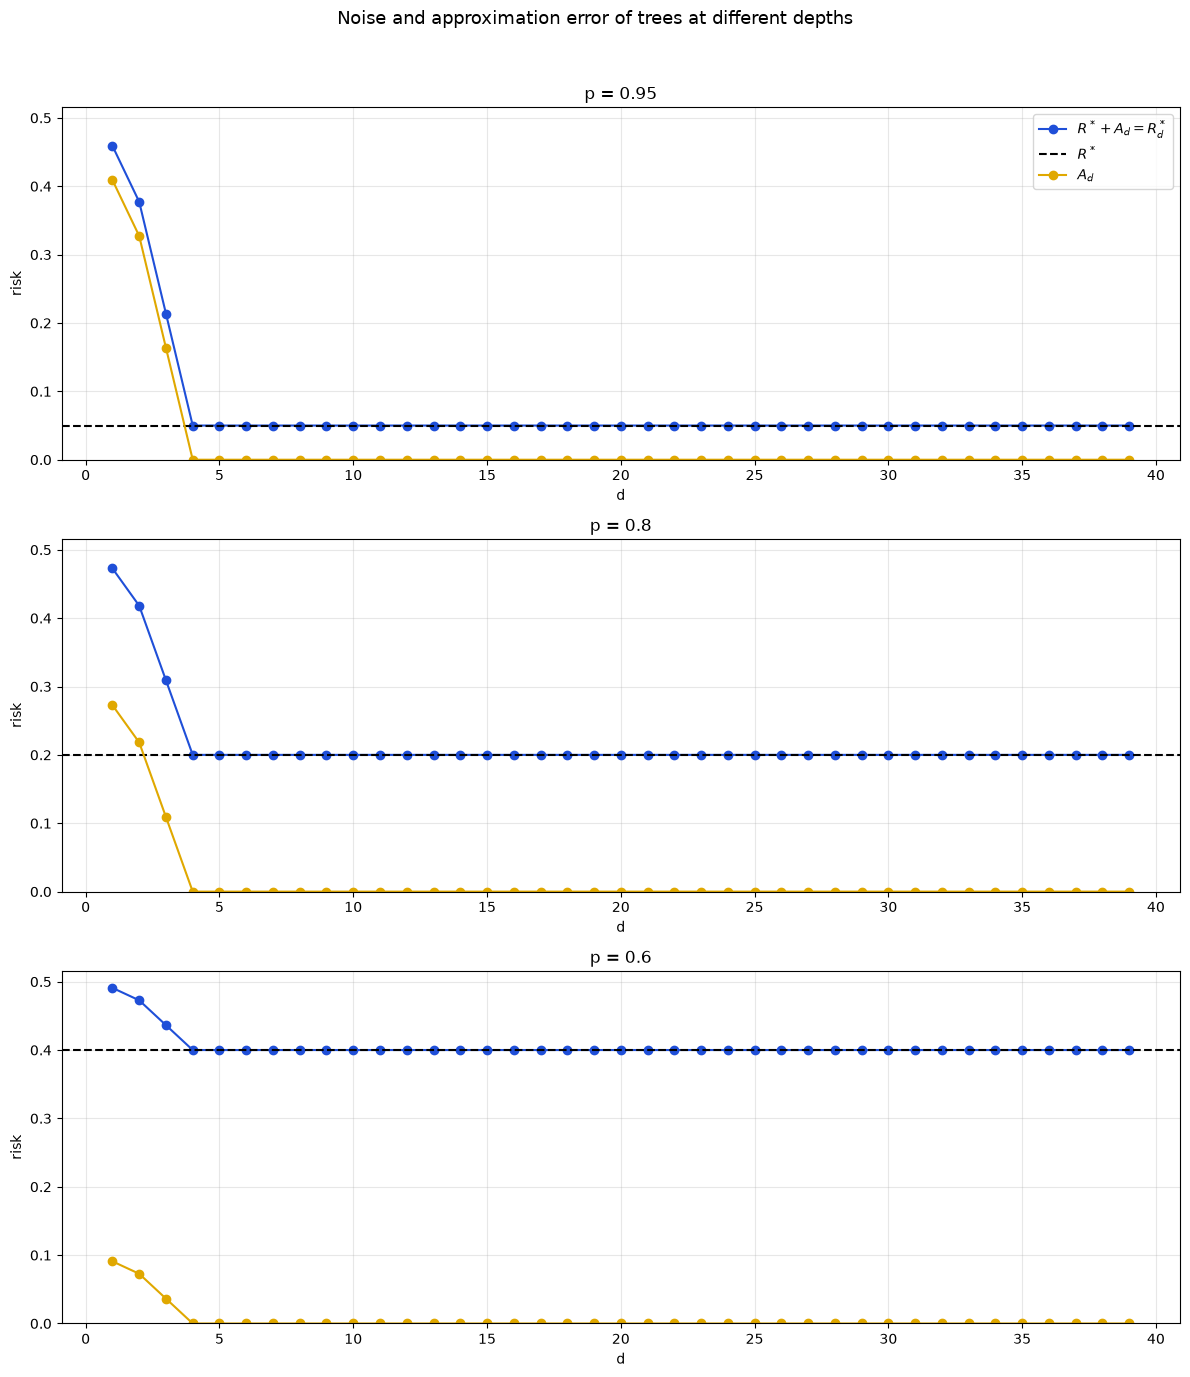

In [22]:
# noises
my_noise_pars = [0.95, 0.8, 0.6]

# R^*_d for each noise level, to reuse in the bounds below
R_star_d_by_p = {}

fig, axs = plt.subplots(3, 1, figsize=(12, 14), sharey=True)
fig.suptitle('Noise and approximation error of trees at different depths', fontsize=13)

for ax, my_noise_par in zip(axs, my_noise_pars):
    my_R_star_d = dp_R_star_d(mysine, depths, N = supp_size, p = my_noise_par)
    my_R_star = 1-my_noise_par
    R_star_d_by_p[my_noise_par] = my_R_star_d

    plot_noise_approxerr(ax, depths, my_R_star_d, my_R_star)
    ax.set_title(f'p = {my_noise_par}')
    if ax is not axs[0]:
        ax.get_legend().remove()

# shared y axis: fix the top by hand, set_ylim(bottom=0) freezes it on the first panel
axs[0].set_ylim(0, 1.05 * max(r.max() for r in R_star_d_by_p.values()))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


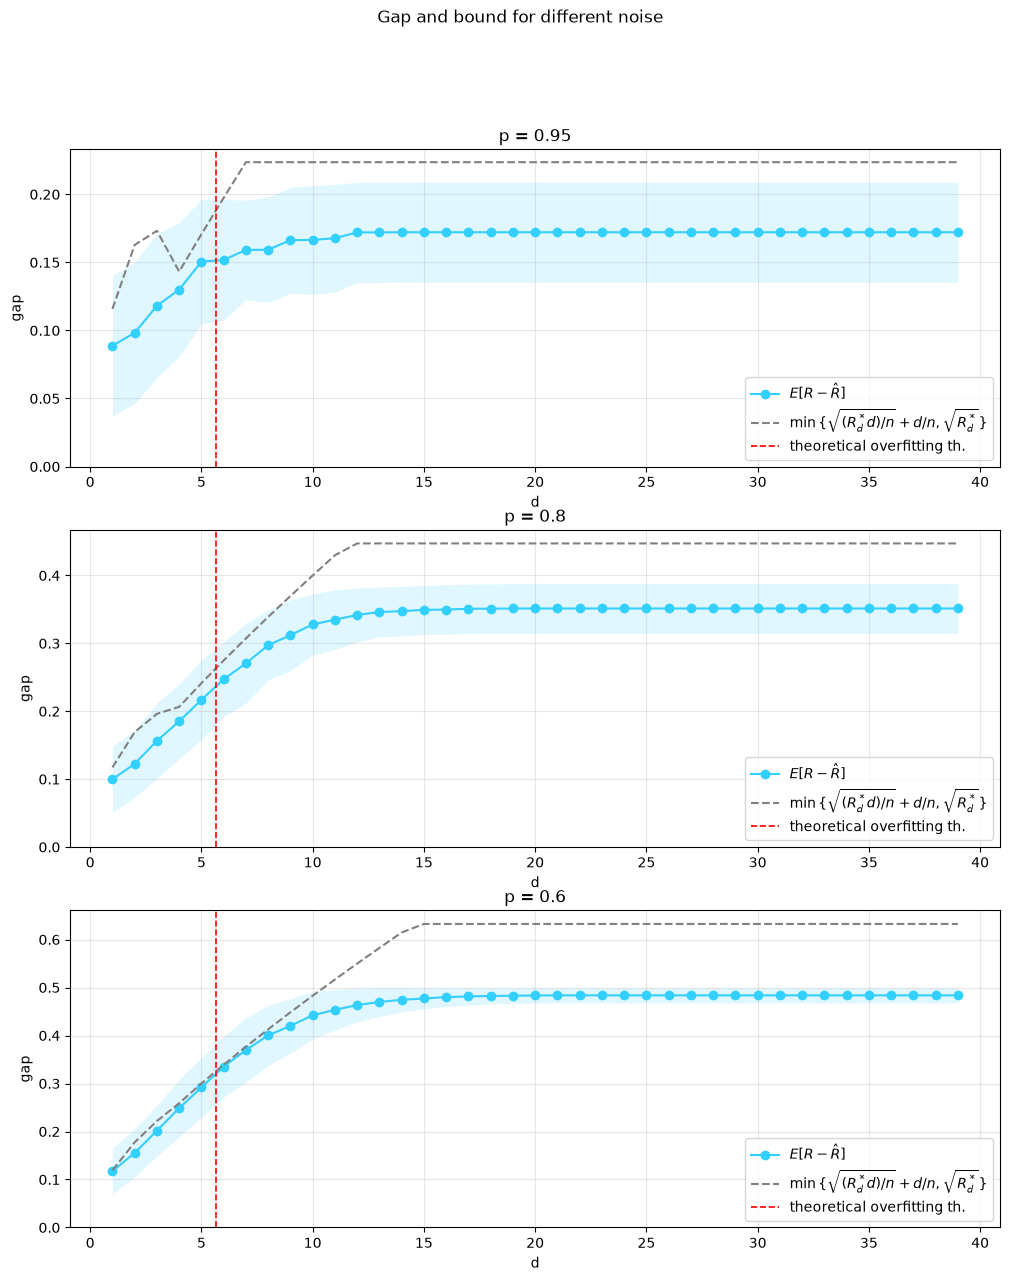

In [19]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('Gap and bound for different noise')

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=mysine, p=my_noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=my_noise_par, T=num_iter, model=mymodel, f=mysine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=my_noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d_by_p[my_noise_par]})
    ax.set_title(f'p = {my_noise_par}')

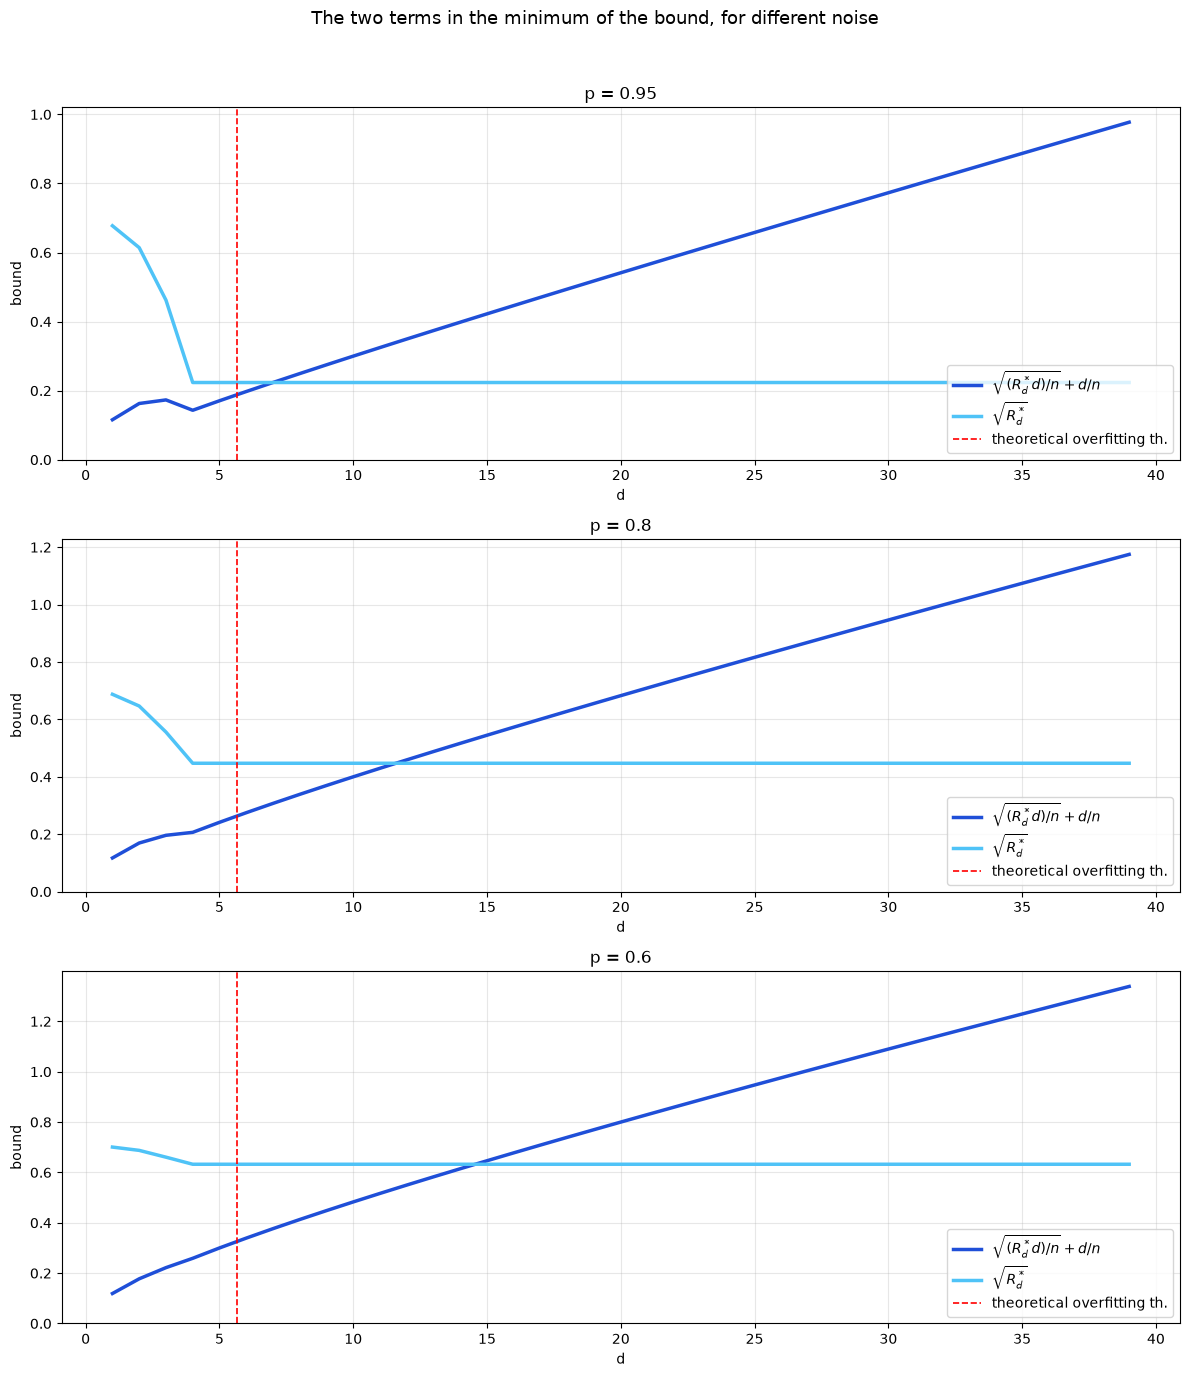

In [23]:
# plot the two terms of the bound 
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('The two terms in the minimum of the bound, for different noise', fontsize=13)

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    my_R_star_d = R_star_d_by_p[my_noise_par]
    log_H = log_card_H(depths)

    # same two terms as in noise_approxerr_bound
    term_one = np.sqrt((my_R_star_d * log_H) / data_size_tr) + log_H / data_size_tr
    term_two = np.sqrt(my_R_star_d)

    ax.plot(depths, term_one, color='#1F4FD8', linewidth=2.5, label=r'$\sqrt{(R^*_d d)/n} + d/n$')
    ax.plot(depths, term_two, color='#4FC3F7', linewidth=2.5, label=r'$\sqrt{R^*_d}$')
    ax.axvline(np.log2(data_size_tr), color='red', linestyle='--', linewidth=1.2, label='theoretical overfitting th.')
    ax.set_ylim(bottom=0)
    ax.set_title(f'p = {my_noise_par}')
    ax.set_xlabel('d'); ax.set_ylabel('bound')
    ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()